In [1]:
from pathlib import Path
from itertools import combinations
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src/snr_sweep.py").is_file():
    raise RuntimeError("Run this notebook from the project root or notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import snr_sweep as sweep
from src.manifests import load_manifest

In [2]:
# Configuration
MODELS = tuple(sweep.MODELS)
SNRS = (20, 50)
NOISE_SEEDS = tuple(sweep.NOISE_SEEDS)
N_TARGET = 1113
N_BOOT = 50_000
BOOT_SEED = 20261010

EDGES = np.round(np.linspace(-0.3, 1.3, 33), 12)
WIDTHS = np.diff(EDGES)
ALL_EDGES = np.r_[-np.inf, EDGES, np.inf]
PAIRS = list(combinations(range(len(MODELS)), 2))
PAIR_LABELS = [f"{MODELS[a]}–{MODELS[b]}" for a, b in PAIRS]

OUT = ROOT / "outputs/cos_lsf_snr/flux_pdf"

# Require existing caches: do not rebuild the forward models here.
cache_dir = ROOT / "outputs/cos_lsf_snr/snr_sweep/clean_flux"
missing = [str(cache_dir / f"{m}.npz")
           for m in MODELS if not (cache_dir / f"{m}.npz").is_file()]
if missing:
    raise FileNotFoundError("Missing clean-flux caches:\n" + "\n".join(missing))

manifest = load_manifest(
    ROOT / "outputs/uvb_mean_flux/manifests/z0_b15_seed42.npz"
)

In [3]:
bundle_ids = np.sort(manifest["test_bundle_ids"])
bundle_los = np.asarray(manifest["bundles"][bundle_ids], dtype=int)
n_bundles, bundle_size = bundle_los.shape
n_reference = bundle_los.size

if np.unique(bundle_los).size != n_reference:
    raise RuntimeError("Held-out bundles contain repeated sightlines.")

# Axes: S/N, model, noise seed, bundle, flux bin including both tails.
bundle_p = np.empty(
    (len(SNRS), len(MODELS), len(NOISE_SEEDS), n_bundles, 34)
)
source_metadata = {}

In [4]:
for m, model in enumerate(MODELS):
    clean, dv, metadata = sweep.cache_lp1_flux(model, ROOT)
    source_metadata[model] = metadata

    for s, snr in enumerate(SNRS):
        for r, seed in enumerate(NOISE_SEEDS):
            # Generate noise on ALL sightlines in their original order.
            noisy = sweep.add_noise(
                clean, snr, model=model, noise_seed=int(seed)
            )
            blocks = noisy[bundle_los].reshape(n_bundles, -1)
            counts = np.array([
                np.histogram(row, bins=ALL_EDGES)[0] for row in blocks
            ])
            # Normalize by all pixels; retain underflow and overflow.
            bundle_p[s, m, r] = counts / blocks.shape[1]
            del noisy, blocks
    del clean

np.testing.assert_allclose(
    bundle_p.sum(axis=-1), 1.0, rtol=0, atol=1e-12
)

# Mean model PDFs: average the three noise realizations.
mean_p = bundle_p.mean(axis=(2, 3))

# Bundle-bootstrap weights. Since the PDF is a linear mean, propagating
# their covariance exactly reproduces the covariance of these resamples.
rng = np.random.default_rng(BOOT_SEED)
weights = rng.multinomial(
    n_bundles, np.full(n_bundles, 1 / n_bundles), size=N_BOOT
).astype(float) / n_bundles
weight_cov = np.cov(weights, rowvar=False, ddof=1)
del weights

cov_target = np.zeros((len(SNRS), len(MODELS), 34, 34))
for s, m, r in np.ndindex(
    len(SNRS), len(MODELS), len(NOISE_SEEDS)
):
    x = bundle_p[s, m, r]
    centered = x - x.mean(axis=0)
    cov_target[s, m] += (
        centered.T @ weight_cov @ centered
    ) / len(NOISE_SEEDS)

# Average within-seed covariances: three seeds are NOT three surveys.
cov_target *= n_reference / N_TARGET
variance = np.diagonal(
    cov_target, axis1=-2, axis2=-1
)[..., 1:-1]

EX0: reused EX0.npz
EX1: reused EX1.npz
EX2: reused EX2.npz
EX3: reused EX3.npz


In [5]:
def interval_80(score):
    """Shortest contiguous set of bins containing >=80% of the score."""
    cumulative = np.r_[0.0, np.cumsum(score)]
    total = cumulative[-1]
    if total <= 0:
        return np.nan, np.nan, np.nan

    for width in range(1, len(score) + 1):
        enclosed = cumulative[width:] - cumulative[:-width]
        eligible = np.flatnonzero(enclosed >= 0.8 * total)
        if eligible.size:
            # Tie-break: retain the interval containing more contrast.
            start = int(eligible[np.argmax(enclosed[eligible])])
            return (
                float(EDGES[start]),
                float(EDGES[start + width]),
                float(100 * enclosed[start] / total),
            )

In [6]:
chi = np.zeros((len(SNRS), len(PAIRS), len(WIDTHS)))
summary_rows, bin_tables = [], []

for s, snr in enumerate(SNRS):
    for k, (a, b) in enumerate(PAIRS):
        delta = mean_p[s, a, 1:-1] - mean_p[s, b, 1:-1]
        pair_variance = (variance[s, a] + variance[s, b]) / 2

        if np.any(pair_variance < 0):
            raise RuntimeError("Negative bootstrap variance.")
        if np.any((pair_variance == 0) & (delta != 0)):
            raise RuntimeError(
                f"Zero variance with nonzero contrast: "
                f"S/N={snr}, {PAIR_LABELS[k]}"
            )

        chi[s, k] = np.divide(
            delta**2, pair_variance,
            out=np.zeros_like(delta), where=pair_variance > 0
        )
        score = chi[s, k]
        total = score.sum()
        lo, hi, enclosed_pct = interval_80(score)

        below_pct = (
            100 * score[EDGES[1:] <= 0.85].sum() / total
            if total > 0 else np.nan
        )
        summary_rows.append({
            "SNR": snr,
            "pair": PAIR_LABELS[k],
            "F80_low": lo,
            "F80_high": hi,
            "contrast_in_F80_pct": enclosed_pct,
            "contrast_below_0p85_pct": below_pct,
        })

        bin_tables.append(pd.DataFrame({
            "SNR": snr,
            "pair": PAIR_LABELS[k],
            "flux_low": EDGES[:-1],
            "flux_high": EDGES[1:],
            "pdf_A": mean_p[s, a, 1:-1] / WIDTHS,
            "pdf_B": mean_p[s, b, 1:-1] / WIDTHS,
            "sigma_pdf": np.sqrt(pair_variance) / WIDTHS,
            "chi2_bin": score,
            "cumulative_diagonal_chi2": np.cumsum(score),
        }))

summary = pd.DataFrame(summary_rows)

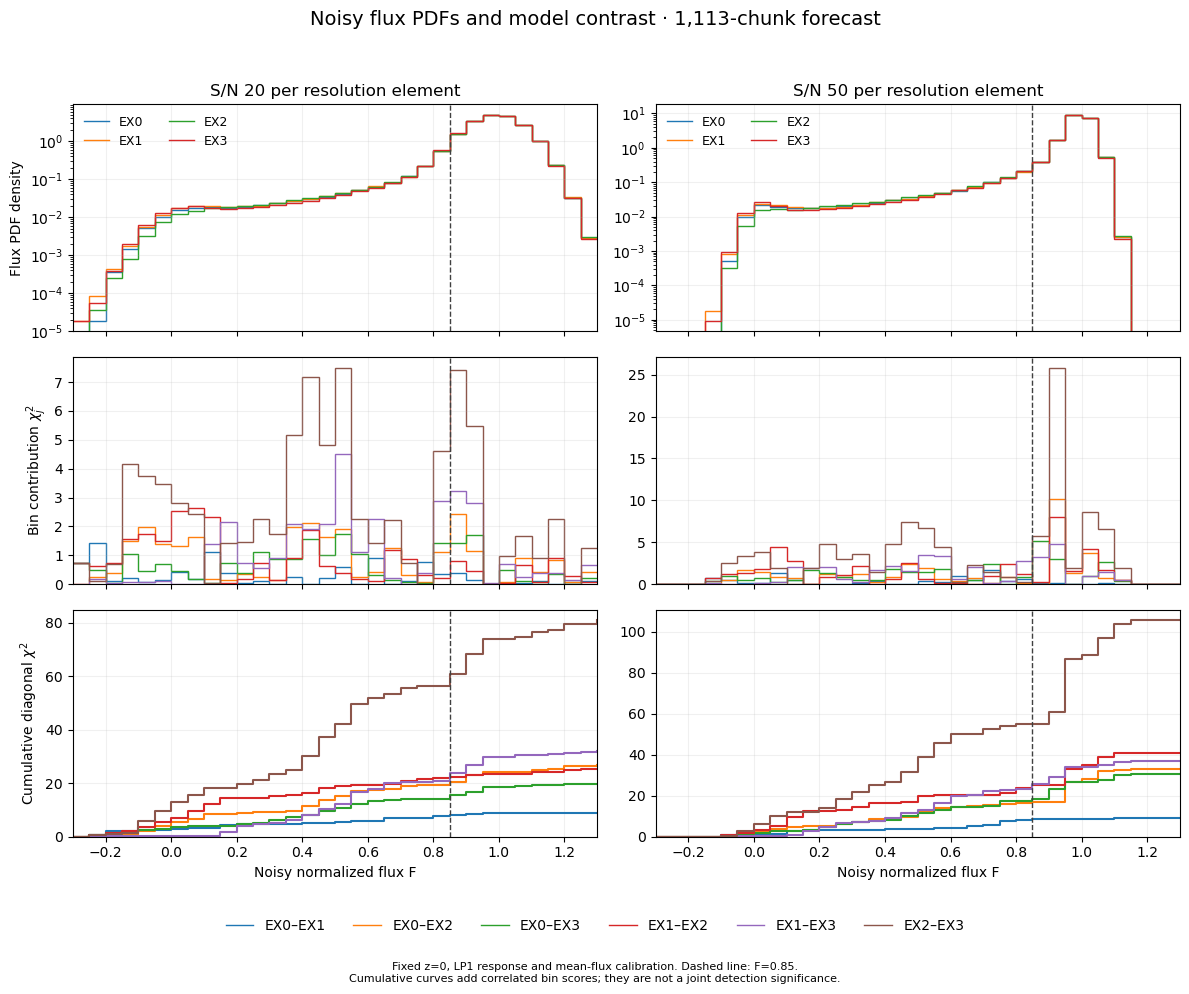

,SNR,pair,F80_low,F80_high,contrast_in_F80_pct,contrast_below_0p85_pct
0,20,EX0–EX1,-0.30,0.80,86.33,90.08
1,20,EX0–EX2,-0.15,0.90,83.24,76.56
2,20,EX0–EX3,-0.10,0.95,81.86,77.90
3,20,EX1–EX2,-0.25,0.75,81.91,86.92
4,20,EX1–EX3,0.15,0.95,86.46,73.45
5,20,EX2–EX3,-0.10,0.95,84.24,75.36
6,50,EX0–EX1,0.00,0.85,80.61,94.83
7,50,EX0–EX2,0.20,1.05,80.32,50.41
8,50,EX0–EX3,0.20,1.10,82.60,60.34
9,50,EX1–EX2,0.05,1.05,82.47,60.88


Reference: 134 bundles × 15 = 2010 chunks
Standard-error scaling: 1.343849
Largest probability outside plotted range: 0.0010%
Saved to: outputs/cos_lsf_snr/flux_pdf


In [ ]:
# Meeting figure: PDFs, per-bin contrast, cumulative diagonal contrast.
fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=True)
model_colors = plt.get_cmap("tab10").colors[:len(MODELS)]
pair_colors = plt.get_cmap("tab10").colors[:len(PAIRS)]

for s, snr in enumerate(SNRS):
    axes[0, s].set_title(f"S/N {snr} per resolution element")
    for m, model in enumerate(MODELS):
        axes[0, s].stairs(
            mean_p[s, m, 1:-1] / WIDTHS, EDGES,
            baseline=None, color=model_colors[m], label=model
        )
    axes[0, s].set_yscale("log")
    axes[0, s].legend(ncol=2, fontsize=9, frameon=False)

    for k, label in enumerate(PAIR_LABELS):
        axes[1, s].stairs(
            chi[s, k], EDGES, baseline=None,
            color=pair_colors[k], label=label
        )
        axes[2, s].step(
            EDGES, np.r_[0.0, np.cumsum(chi[s, k])],
            where="post", color=pair_colors[k]
        )

    axes[1, s].set_ylim(bottom=0)
    axes[2, s].set_ylim(bottom=0)
    axes[2, s].set_xlabel("Noisy normalized flux F")

axes[0, 0].set_ylabel("Flux PDF density")
axes[1, 0].set_ylabel(r"Bin contribution $\chi^2_j$")
axes[2, 0].set_ylabel(r"Cumulative diagonal $\chi^2$")

for ax in axes.flat:
    ax.axvline(0.85, color="0.25", linestyle="--", linewidth=1)
    ax.set_xlim(EDGES[0], EDGES[-1])
    ax.grid(alpha=0.18)

fig.suptitle(
    "Noisy flux PDFs and model contrast · 1,113-chunk forecast",
    fontsize=14
)
handles, labels = axes[1, 0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="lower center",
    bbox_to_anchor=(0.5, 0.045), ncol=6, frameon=False
)
fig.text(
    0.5, 0.008,
    "Fixed z=0, LP1 response and mean-flux calibration. "
    "Dashed line: F=0.85.\n"
    "Cumulative curves add correlated bin scores; "
    "they are not a joint detection significance.",
    ha="center", fontsize=8
)
fig.tight_layout(rect=(0, 0.095, 1, 0.955))

# Save figures, per-bin results, full covariances and provenance.
OUT.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT / "flux_pdf_contrast.pdf", bbox_inches="tight")
fig.savefig(
    OUT / "flux_pdf_contrast.png", dpi=220, bbox_inches="tight"
)
summary.to_csv(OUT / "flux_ranges.csv", index=False)
pd.concat(bin_tables, ignore_index=True).to_csv(
    OUT / "pairwise_bins.csv", index=False
)
np.savez_compressed(
    OUT / "bootstrap_inputs_results.npz",
    flux_edges=EDGES,
    models=np.array(MODELS),
    snrs=np.array(SNRS),
    noise_seeds=np.array(NOISE_SEEDS),
    pair_labels=np.array(PAIR_LABELS),
    bundle_ids=bundle_ids,
    bundle_los=bundle_los,
    bundle_probabilities_with_tails=bundle_p,
    mean_probabilities_with_tails=mean_p,
    covariance_target_with_tails=cov_target,
    bootstrap_weight_covariance=weight_cov,
    chi2_bins=chi,
)
provenance = {
    "target_chunks": N_TARGET,
    "reference_chunks": int(n_reference),
    "reference_bundles": int(n_bundles),
    "bootstrap_draws": N_BOOT,
    "bootstrap_seed": BOOT_SEED,
    "variance_scale": float(n_reference / N_TARGET),
    "noise_seeds": [int(x) for x in NOISE_SEEDS],
    "snr_per_resolution_element": list(SNRS),
    "mean_flux_reference": POWER_MEAN,
    "mean_flux_reference_source": "Calibrated EX0 training mean",
    "power": (
        "Common-mean normalization: delta = flux/reference - 1; "
        "P = dv/N * abs(rfft(delta))^2"
    ),
    "noise_floor": "sigma_bin^2 * dv / reference^2",
    "pair_variance": "Average of model-specific single-survey variances",
    "noise_variance_policy": "Average covariances computed separately per seed",
    "normalization": "All pixels; retain tails F < -0.3 and F >= 1.3",
    "range_definition": "Shortest contiguous interval with >=80% displayed contrast",
    "cut_definition": "Noisy F < 0.85 within displayed [-0.3, 1.3] range",
    "forecast_assumption": "1113 independent chunks; fixed z=0, LP1 and calibration",
    "source_metadata": source_metadata,
    "numpy_version": np.__version__,
}
(OUT / "provenance.json").write_text(
    json.dumps(provenance, indent=2), encoding="utf-8"
)

plt.show()
display(summary.round(2))
tail_mass = mean_p[..., [0, -1]].sum(axis=-1)
print(f"Reference: {n_bundles} bundles × {bundle_size} = {n_reference} chunks")
print(f"Standard-error scaling: {np.sqrt(n_reference / N_TARGET):.6f}")
print(f"Largest probability outside plotted range: {100 * tail_mass.max():.4f}%")
print(f"Saved to: {OUT.relative_to(ROOT)}")

In [7]:
import h5py
from src import build_cos_features as cos
from src import instrument

In [8]:
PK_OUT = ROOT / "outputs/cos_lsf_snr/flux_power"
PK_OUT.mkdir(parents=True, exist_ok=True)

In [23]:
assert MODELS[0] == "EX0"
n_bundles, bundle_size = bundle_los.shape
los_order = bundle_los.ravel()
sorted_los = np.sort(los_order)
restore_order = np.searchsorted(sorted_los, los_order)

L = 2500.0
dv_lp1 = L / cos.LP1_N_PIXELS_OUT
dv_native = L / 2499

calibration = json.loads(
    (ROOT / "outputs/uvb_mean_flux/calibration/z0_b15_seed42.json")
    .read_text()
)
POWER_MEAN = float(
    calibration["results"]["EX0"]["matched_train_mean_flux"]
)
if not np.isfinite(POWER_MEAN) or POWER_MEAN <= 0:
    raise ValueError("Invalid common mean-flux reference.")

In [24]:
# Common Fourier modes for native and LP1 spectra.
# Exclude DC and the even-length LP1 Nyquist mode.
modes = np.arange(1, cos.LP1_N_PIXELS_OUT // 2)
k_modes = 2 * np.pi * modes / L
k_edges = np.geomspace(k_modes[0], np.pi / dv_lp1, 21)
k_edges[0] = np.nextafter(k_edges[0], 0.0)

membership = (
    (k_modes[None, :] >= k_edges[:-1, None])
    & (k_modes[None, :] < k_edges[1:, None])
)
occupied = membership.sum(axis=1) > 0
membership = membership[occupied]
mode_counts = membership.sum(axis=1)
bin_weights = membership / mode_counts[:, None]

k = bin_weights @ k_modes
k_low = k_edges[:-1][occupied]
k_high = k_edges[1:][occupied]
nk = len(k)

In [25]:
def chunk_bandpowers(flux, dv):
    """Repo normalization: P = (dv/N) |FFT(F/mean(F) - 1)|^2."""
    flux = np.asarray(flux, dtype=float)
    if flux.shape[0] != n_reference:
        raise ValueError("Unexpected number of held-out chunks.")
    if not np.isclose(flux.shape[1] * dv, L):
        raise ValueError("Chunk velocity length changed.")

    if not np.all(np.isfinite(flux)):
        raise ValueError("Flux contains non-finite values.")

    means = flux.mean(axis=1)  # Retain actual means for diagnostics/checks.
    delta = flux / POWER_MEAN - 1.0
    ft = np.fft.rfft(delta, axis=1)
    raw_power = (dv / flux.shape[1]) * np.abs(ft[:, modes])**2
    binned = raw_power @ bin_weights.T
    bundled = binned.reshape(n_bundles, bundle_size, nk).mean(axis=1)
    return bundled, means

In [26]:
# Axes: S/N, noise realization, model, bundle, k bin.
noisy_power = np.empty(
    (len(SNRS), len(NOISE_SEEDS), len(MODELS), n_bundles, nk)
)
white_bundle = np.empty(noisy_power.shape[:-1])
native_power = np.empty((1, len(MODELS), n_bundles, nk))
clean_power = np.empty_like(native_power)
power_sources = {}

In [27]:
for m, model in enumerate(MODELS):
    clean_all, dv, metadata = sweep.cache_lp1_flux(model, ROOT)
    power_sources[model] = metadata
    clean_test = clean_all[los_order]
    clean_power[0, m], clean_means = chunk_bandpowers(clean_test, dv)

    # Read native spectra in sorted order for h5py, then restore bundle order.
    with h5py.File(ROOT / "data/raw" / f"{model}_spectra.hdf5", "r") as f:
        tau = np.asarray(
            f[calibration["tau_key"]][sorted_los, :], dtype=float
        )[restore_order]

    if (
        tau.shape != (n_reference, 2499)
        or not np.all(np.isfinite(tau))
        or np.any(tau < 0)
    ):
        raise ValueError(f"Invalid native optical depths for {model}.")

    native = np.exp(-metadata["tau_scale"] * tau)
    del tau
    native_power[0, m], native_means = chunk_bandpowers(native, dv_native)
    np.testing.assert_allclose(
        native_means, clean_means, rtol=0, atol=1e-12
    )
    del native

    for s, snr in enumerate(SNRS):
        sigma = sweep.sigma_per_bin(snr)
        for r, seed in enumerate(NOISE_SEEDS):
            # Preserve the exact noise draws used by the S/N sweep.
            noisy_all = sweep.add_noise(
                clean_all, snr, model=model, noise_seed=int(seed)
            )
            noisy_power[s, r, m], means = chunk_bandpowers(
                noisy_all[los_order], dv
            )

            # Same per-chunk normalization as the measured power.
            white_bundle[s, r, m] = sigma**2 * dv / POWER_MEAN**2
            del noisy_all

    del clean_all, clean_test

EX0: reused EX0.npz
EX1: reused EX1.npz
EX2: reused EX2.npz
EX3: reused EX3.npz


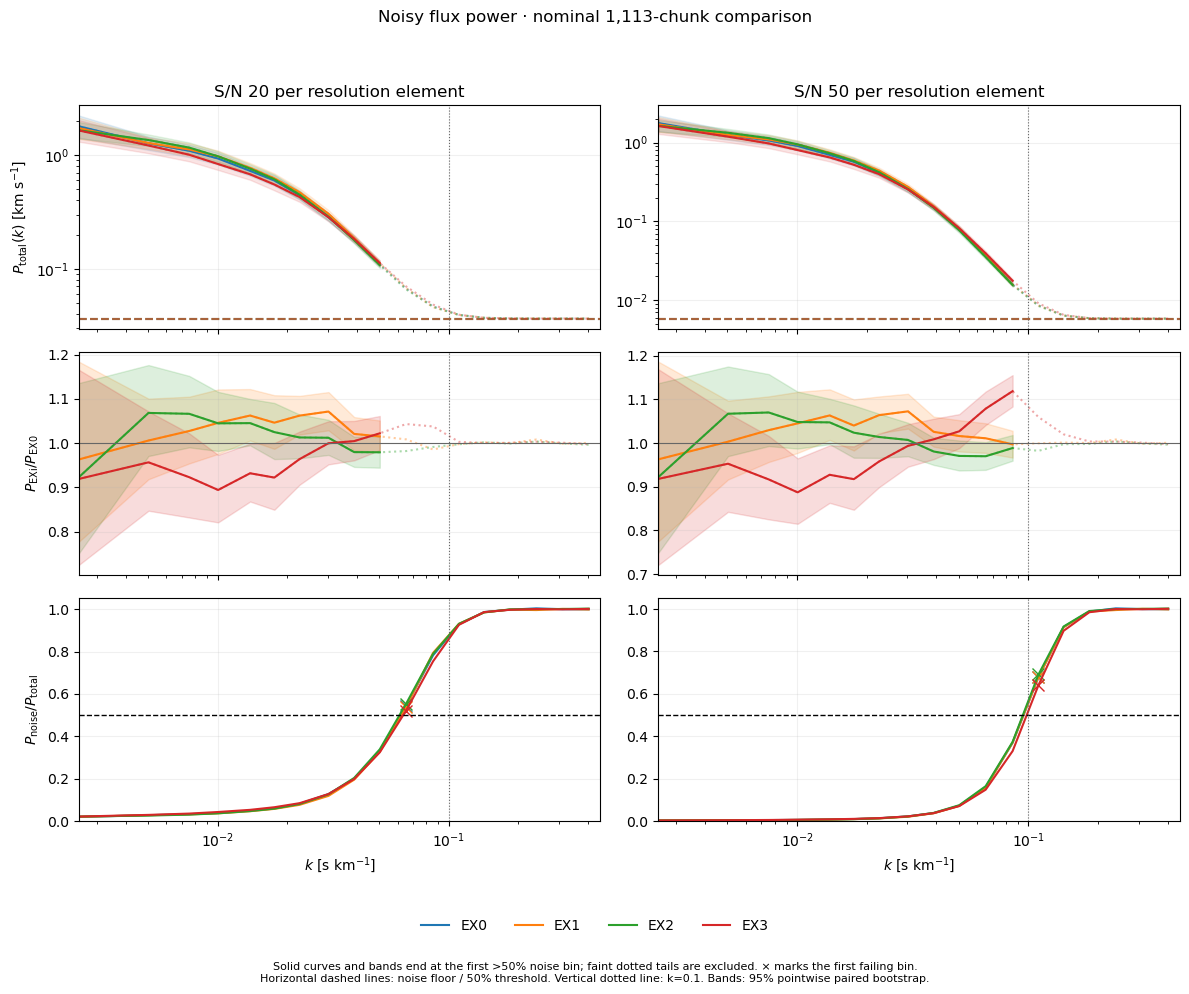

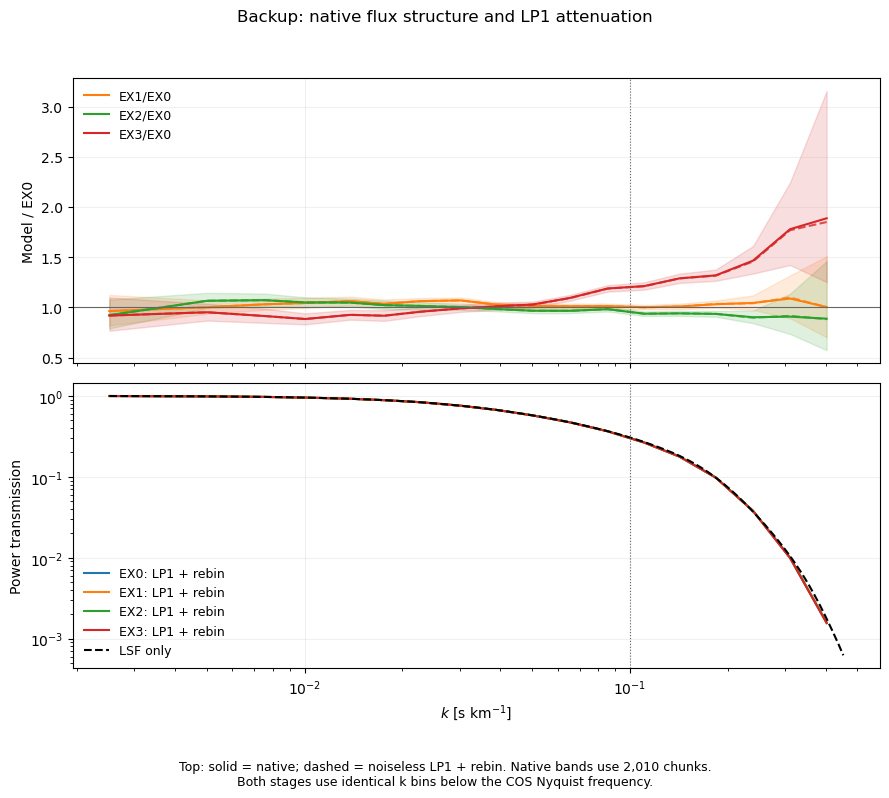

,SNR,model,usable_k_max_bin_edge,first_noise_dominated_k,power_ratio_to_EX0_usable_k_max_bin_edge
0,20,EX0,0.0569,0.0653,0.0569
1,20,EX1,0.0569,0.0653,0.0569
2,20,EX2,0.0569,0.0653,0.0569
3,20,EX3,0.0569,0.0653,0.0569
4,50,EX0,0.0956,0.1106,0.0956
5,50,EX1,0.0956,0.1106,0.0956
6,50,EX2,0.0956,0.1106,0.0956
7,50,EX3,0.0956,0.1106,0.0956


,k,native_ratio,native_lo,native_hi,LP1_clean_ratio,EX3_power_transmission,noisy_ratio_SNR20,usable_SNR20,noisy_ratio_SNR50,usable_SNR50
9,0.0503,1.0285,0.9997,1.0576,1.0273,0.5734,1.0221,True,1.0268,True
10,0.0653,1.0937,1.0652,1.1235,1.0916,0.4711,1.0430,False,1.0785,True
11,0.0855,1.1879,1.1564,1.2209,1.1870,0.3649,1.0376,False,1.1185,True
12,0.1106,1.2117,1.1755,1.2496,1.2102,0.2652,1.0027,False,1.0592,False
13,0.1420,1.2885,1.2427,1.3360,1.2885,0.1776,1.0002,False,1.0199,False
14,0.1835,1.3186,1.2640,1.3762,1.3157,0.0977,1.0006,False,1.0035,False
15,0.2388,1.4648,1.3360,1.6100,1.4564,0.0379,1.0031,False,1.0033,False
16,0.3104,1.7783,1.4213,2.2447,1.7682,0.0099,1.0009,False,1.0009,False
17,0.4021,1.8869,1.2520,3.1548,1.8497,0.0016,0.9975,False,0.9975,False


Saved to: outputs/cos_lsf_snr/flux_power


In [29]:
# Shared bundle draws preserve the pairing of simulation fields.
rng = np.random.default_rng(BOOT_SEED)
pk_weights = rng.multinomial(
    n_bundles, np.full(n_bundles, 1 / n_bundles), size=N_BOOT
).astype(float) / n_bundles


def power_bootstrap(values, target_chunks):
    """
    values: realization, model, bundle, k.

    Pool separately centered bootstrap residuals across noise realizations.
    This preserves single-realization uncertainty: three seeds do not
    count as three observed surveys.
    """
    mean_power = values.mean(axis=(0, 2))
    residuals = []

    for one_seed in values:
        flat = one_seed.transpose(1, 0, 2).reshape(n_bundles, -1)
        draws = (pk_weights @ flat).reshape(N_BOOT, len(MODELS), nk)
        seed_mean = one_seed.mean(axis=1)

        if np.any(draws <= 0) or np.any(seed_mean <= 0):
            raise RuntimeError("Nonpositive power in bootstrap.")

        residuals.append(np.log(draws / seed_mean[None]))

    residuals = np.concatenate(residuals, axis=0)
    scale = np.sqrt(n_reference / target_chunks)

    q_power = np.quantile(
        residuals, [0.025, 0.975], axis=0
    ) * scale
    q_ratio = np.quantile(
        residuals - residuals[:, :1],
        [0.025, 0.975], axis=0
    ) * scale

    ratio = mean_power / mean_power[:1]
    return (
        mean_power,
        mean_power[None] * np.exp(q_power),
        ratio,
        ratio[None] * np.exp(q_ratio),
    )


pk_results = [
    power_bootstrap(noisy_power[s], N_TARGET) for s in range(len(SNRS))
]
# Native backup describes the actual held-out simulation sample.
native_result = power_bootstrap(native_power, n_reference)
clean_mean = clean_power.mean(axis=(0, 2))
clean_ratio = clean_mean / clean_mean[:1]

white_level = white_bundle.mean(axis=(1, 3))
noise_fraction = np.stack([
    white_level[s, :, None] / pk_results[s][0]
    for s in range(len(SNRS))
])

# Stop permanently at the FIRST bin exceeding 50% noise.
stops = np.full((len(SNRS), len(MODELS)), nk, dtype=int)
cut_rows = []
curve_tables = []

for s, snr in enumerate(SNRS):
    power, power_ci, ratio, ratio_ci = pk_results[s]

    for m, model in enumerate(MODELS):
        failed = np.flatnonzero(noise_fraction[s, m] > 0.5)
        if failed.size:
            stops[s, m] = int(failed[0])

    for m, model in enumerate(MODELS):
        stop = stops[s, m]
        pair_stop = min(stop, stops[s, 0])

        cut_rows.append({
            "SNR": snr,
            "model": model,
            "usable_k_max_bin_edge": (
                k_high[stop - 1] if stop > 0 else np.nan
            ),
            "first_noise_dominated_k": (
                k[stop] if stop < nk else np.nan
            ),
            "power_ratio_to_EX0_usable_k_max_bin_edge": (
                k_high[pair_stop - 1] if pair_stop > 0 else np.nan
            ),
        })
        curve_tables.append(pd.DataFrame({
            "SNR": snr,
            "model": model,
            "k": k,
            "k_low": k_low,
            "k_high": k_high,
            "mode_count": mode_counts,
            "P_total": power[m],
            "P_lo": power_ci[0, m],
            "P_hi": power_ci[1, m],
            "P_noise": white_level[s, m],
            "noise_fraction": noise_fraction[s, m],
            "ratio_to_EX0": ratio[m],
            "ratio_lo": ratio_ci[0, m],
            "ratio_hi": ratio_ci[1, m],
            "ratio_usable": np.arange(nk) < pair_stop,
        }))

cutoffs = pd.DataFrame(cut_rows)

# Exact LSF-only power transfer for the kernel used by the forward model.
wavelengths, kernels = instrument.load_cos_lsf(ROOT / cos.LP1_LSF_PATH)
column = int(np.argmin(abs(wavelengths - cos.LP1_WAVELENGTH_A)))
dv_lsf = (
    cos.C_KMS * cos.LP1_DISPERSION_A_PER_PIXEL / wavelengths[column]
)
kernel = instrument.resample_lsf(kernels[:, column], dv_lsf, dv_native)
offsets = (np.arange(kernel.size) - kernel.size // 2) * dv_native


def lsf_power_transfer(k_values):
    return np.abs(
        np.exp(-1j * np.asarray(k_values)[:, None] * offsets) @ kernel
    )**2


k_fine = np.geomspace(k_modes[0], k_modes[-1], 500)
transfer_fine = lsf_power_transfer(k_fine)

# Main figure.
colors = plt.get_cmap("tab10").colors[:len(MODELS)]
fig_pk, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=True)

for s, snr in enumerate(SNRS):
    power, power_ci, ratio, ratio_ci = pk_results[s]
    axes[0, s].set_title(f"S/N {snr} per resolution element")

    for m, model in enumerate(MODELS):
        color = colors[m]
        good = np.arange(nk) < stops[s, m]

        axes[0, s].plot(k, power[m], ":", color=color, alpha=0.4)
        axes[0, s].plot(k[good], power[m, good], color=color, label=model)
        axes[0, s].fill_between(
            k[good], power_ci[0, m, good], power_ci[1, m, good],
            color=color, alpha=0.12
        )
        axes[0, s].axhline(
            white_level[s, m], color=color, linestyle="--", alpha=0.5
        )

        axes[2, s].plot(k, noise_fraction[s, m], color=color)
        stop = stops[s, m]
        if stop < nk:
            axes[2, s].plot(
                k[stop], noise_fraction[s, m, stop],
                marker="x", color=color, markersize=8
            )

        if m > 0:
            usable = np.arange(nk) < min(stop, stops[s, 0])
            axes[1, s].plot(k, ratio[m], ":", color=color, alpha=0.4)
            axes[1, s].plot(k[usable], ratio[m, usable], color=color)
            axes[1, s].fill_between(
                k[usable], ratio_ci[0, m, usable], ratio_ci[1, m, usable],
                color=color, alpha=0.16
            )

    axes[0, s].set_yscale("log")
    axes[1, s].axhline(1, color="0.4", linewidth=0.8)
    axes[2, s].axhline(0.5, color="black", linestyle="--", linewidth=1)
    axes[2, s].set_ylim(
        0, max(1.05, 1.05 * noise_fraction[s].max())
    )
    axes[2, s].set_xlabel(r"$k$ [s km$^{-1}$]")

axes[0, 0].set_ylabel(r"$P_{\rm total}(k)$ [km s$^{-1}$]")
axes[1, 0].set_ylabel(r"$P_{\rm EXi}/P_{\rm EX0}$")
axes[2, 0].set_ylabel(r"$P_{\rm noise}/P_{\rm total}$")

for ax in axes.flat:
    ax.set_xscale("log")
    ax.set_xlim(k_modes[0], k_modes[-1])
    ax.axvline(0.1, color="0.4", linestyle=":", linewidth=0.8)
    ax.grid(alpha=0.18)

fig_pk.suptitle("Noisy flux power · nominal 1,113-chunk comparison")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig_pk.legend(
    handles, labels, loc="lower center",
    bbox_to_anchor=(0.5, 0.045), ncol=4, frameon=False
)
fig_pk.text(
    0.5, 0.008,
    "Solid curves and bands end at the first >50% noise bin; "
    "faint dotted tails are excluded. × marks the first failing bin.\n"
    "Horizontal dashed lines: noise floor / 50% threshold. "
    "Vertical dotted line: k=0.1. Bands: 95% pointwise paired bootstrap.",
    ha="center", fontsize=8
)
fig_pk.tight_layout(rect=(0, 0.10, 1, 0.95))

# Backup: native physics reference and absolute attenuation.
native_mean, native_ci, native_ratio, native_ratio_ci = native_result
fig_backup, backup_axes = plt.subplots(
    2, 1, figsize=(9, 8), sharex=True
)

for m in range(1, len(MODELS)):
    backup_axes[0].plot(
        k, native_ratio[m], color=colors[m],
        label=f"{MODELS[m]}/EX0"
    )
    backup_axes[0].fill_between(
        k, native_ratio_ci[0, m], native_ratio_ci[1, m],
        color=colors[m], alpha=0.15
    )
    backup_axes[0].plot(
        k, clean_ratio[m], "--", color=colors[m], alpha=0.8
    )

for m, model in enumerate(MODELS):
    backup_axes[1].plot(
        k, clean_mean[m] / native_mean[m],
        color=colors[m], label=f"{model}: LP1 + rebin"
    )
backup_axes[1].plot(
    k_fine, transfer_fine, "k--", label="LSF only"
)
backup_axes[0].axhline(1, color="0.4", linewidth=0.8)
backup_axes[0].set_ylabel("Model / EX0")
backup_axes[1].set_ylabel("Power transmission")
backup_axes[1].set_yscale("log")
backup_axes[1].set_xlabel(r"$k$ [s km$^{-1}$]")

for ax in backup_axes:
    ax.set_xscale("log")
    ax.axvline(0.1, color="0.4", linestyle=":", linewidth=0.8)
    ax.grid(alpha=0.18)
    ax.legend(fontsize=9, frameon=False)

fig_backup.suptitle(
    "Backup: native flux structure and LP1 attenuation"
)
fig_backup.text(
    0.5, 0.01,
    "Top: solid = native; dashed = noiseless LP1 + rebin. "
    "Native bands use 2,010 chunks.\n"
    "Both stages use identical k bins below the COS Nyquist frequency.",
    ha="center", fontsize=9
)
fig_backup.tight_layout(rect=(0, 0.07, 1, 0.95))

# EX3 table for interpretation.
ex3 = MODELS.index("EX3")
ex3_table = pd.DataFrame({
    "k": k,
    "native_ratio": native_ratio[ex3],
    "native_lo": native_ratio_ci[0, ex3],
    "native_hi": native_ratio_ci[1, ex3],
    "LP1_clean_ratio": clean_ratio[ex3],
    "EX3_power_transmission": clean_mean[ex3] / native_mean[ex3],
})
for s, snr in enumerate(SNRS):
    ex3_table[f"noisy_ratio_SNR{snr}"] = pk_results[s][2][ex3]
    ex3_table[f"usable_SNR{snr}"] = (
        np.arange(nk) < min(stops[s, ex3], stops[s, 0])
    )

for figure, stem in (
    (fig_pk, "noisy_power"),
    (fig_backup, "native_ratio_backup"),
):
    figure.savefig(PK_OUT / f"{stem}.pdf", bbox_inches="tight")
    figure.savefig(PK_OUT / f"{stem}.png", dpi=220, bbox_inches="tight")

cutoffs.to_csv(PK_OUT / "noise_cutoffs.csv", index=False)
ex3_table.to_csv(PK_OUT / "ex3_small_scales.csv", index=False)
pd.concat(curve_tables, ignore_index=True).to_csv(
    PK_OUT / "power_curves.csv", index=False
)
np.savez_compressed(
    PK_OUT / "power_inputs_results.npz",
    k=k, k_low=k_low, k_high=k_high, mode_counts=mode_counts,
    models=np.array(MODELS), snrs=np.array(SNRS),
    noise_seeds=np.array(NOISE_SEEDS), bundle_los=bundle_los,
    noisy_bundle_power=noisy_power,
    white_bundle_power=white_bundle,
    native_bundle_power=native_power,
    clean_bundle_power=clean_power,
    noisy_mean=np.stack([r[0] for r in pk_results]),
    noisy_power_ci=np.stack([r[1] for r in pk_results]),
    noisy_ratio=np.stack([r[2] for r in pk_results]),
    noisy_ratio_ci=np.stack([r[3] for r in pk_results]),
    native_ratio=native_ratio, native_ratio_ci=native_ratio_ci,
    k_transfer=k_fine, lsf_power_transfer=transfer_fine,
)
(PK_OUT / "provenance.json").write_text(json.dumps({
    "reference_chunks": int(n_reference),
    "target_chunks": N_TARGET,
    "bootstrap_draws": N_BOOT,
    "bootstrap_seed": BOOT_SEED,
    "bootstrap": (
        "Paired whole bundles; pool within-seed centered log residuals; "
        "scale by sqrt(reference/target); pointwise percentile bands."
    ),
    "power": "Per-chunk mean normalization; dv/N times abs(rfft(delta))^2",
    "noise_subtracted": False,
    "noise_floor": "Mean over chunks of sigma_bin^2 * dv / chunk_mean^2",
    "cutoff": "First bin with noise/total > 0.5; ratio requires both models",
    "native_backup": "Reference-sample intervals; same k bins as LP1",
    "source_metadata": power_sources,
}, indent=2), encoding="utf-8")

plt.show()
display(cutoffs.round(4))
display(ex3_table.loc[ex3_table["k"] >= 0.05].round(4))
print(f"Saved to: {PK_OUT.relative_to(ROOT)}")